In [15]:
import os

workdir = '/vast/ai_projects/Papenfuss_SVEnsemble2/model/'
os.chdir(workdir)
os.getcwd()

import copy
import importlib
import re

import numpy as np
import pandas as pd
import matplotlib as mpl
import pyranges as pr

import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve

import vcfparser as vcfp
import bndconvert as bndc
import sve_benchmark as benchmark
import callset_handler as clhd

importlib.reload(vcfp)
importlib.reload(bndc)
importlib.reload(benchmark)
importlib.reload(clhd)

<module 'callset_handler' from '/vast/ai_projects/Papenfuss_SVEnsemble2/model/callset_handler.py'>

In [3]:
pd.set_option('display.max_columns', None)

pu_preds_path = 'saved/y_duplessis_enoto_bps.csv'

In [4]:
# Check if running in SLURM job by looking for SLURM environment variables
is_slurm = 'SLURM_JOB_ID' in os.environ
print(f"Running in SLURM job: {is_slurm}")


Running in SLURM job: True


In [5]:
# I use reference derived by algorithm described by Kosugi
# With dgv version for year 2020 instead of 2016

# ref_path = '../reference/saved/NA12878.reference.tsv'
# ref_df = pd.read_csv(ref_path, sep='\t', index_col='Unnamed: 0')
# ref_df = ref_df[ref_df['ALT'] == 'deletion']



ref_df = benchmark.load_truth_variants('data/NA12878_DGV-2016_LR-assembly.hg38.bed')
ref_vcf = benchmark.truth_to_vcf_df(ref_df, ref_match_margin=50)

# ref_df_pr = ref_df_pr[(ref_df_pr['length'] > 1000) & (ref_df_pr['length'] < 100000)]
# ref_df = ref_df[ref_df['ALT'] == 'DEL']
# ref_df_pr = ref_df_pr[ref_df_pr['length'] > 50]


ref_vcf_bps = benchmark.truth_event_to_bnd(ref_vcf)
ref_vcf_bps_dels = ref_vcf_bps[ref_vcf_bps['INFO_SVTYPE'] == 'DEL']
ref_vcf_bps_dels_long = ref_vcf_bps_dels[ref_vcf_bps_dels['INFO_SVLEN'] > 50]

/vast/ai_projects/Papenfuss_SVEnsemble2/model/bndconvert.py:631: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  encodings = encoding_df.idxmax(axis=1)


In [6]:
# ref_vcf_bps_dels[ref_vcf_bps_dels['INFO_SVLEN'] > 50]

In [19]:
# Load and parse GRIDSS VCF output
gridss_callset_path = 'data/test_gridss_output.NA12878.vcf'
try:
    gridss_callset_raw
except NameError:
    gridss_callset_raw = vcfp.parse_vcf(gridss_callset_path, line_limit=None, skip_format=True)

gridss_callset_bps = clhd.gridss_to_bp(gridss_callset_raw)
# Annotate deletions in the breakpoint pairs
gridss_callset_bps = pd.concat([gridss_callset_bps, bndc.annotate_deletions(gridss_callset_bps)], axis=1)

/vast/ai_projects/Papenfuss_SVEnsemble2/model/bndconvert.py:631: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  encodings = encoding_df.idxmax(axis=1)


0        NaN
1        NaN
2        NaN
3        NaN
4        NaN
          ..
197355   NaN
197356   NaN
197357   NaN
197358   NaN
197359   NaN
Name: 0, Length: 197360, dtype: float64
0        NaN
1        NaN
2        NaN
3        NaN
4        NaN
          ..
197355   NaN
197356   NaN
197357   NaN
197358   NaN
197359   NaN
Name: 0, Length: 197360, dtype: float64
0        NaN
1        NaN
2        NaN
3        NaN
4        NaN
          ..
197355   NaN
197356   NaN
197357   NaN
197358   NaN
197359   NaN
Name: 0, Length: 197360, dtype: float64
0               706
1         123713378
2         124955543
3           9673463
4          49167045
            ...    
197355    -10737043
197356     32273986
197357    -48199195
197358    -11560421
197359    -64128501
Length: 197360, dtype: int64


In [23]:
gridss_callset_bps['ALT_bnd2']

0          [chr1:6558931[G
1          [chr1:6705183[A
2          [chr1:6709788[A
3          [chr1:6740259[A
4          [chr1:7392267[A
                ...       
197355    T]chr1:93409750]
197356    C]chr1:93411558]
197357    T]chr1:93427807]
197358    C]chr1:93427833]
197359    C]chr1:93464339]
Name: ALT_bnd2, Length: 197360, dtype: object

In [22]:
gridss_callset_bps[~gridss_callset_bps['ALT_bnd2'].str.extract(r'([ATGCNatgcn]+)\[').isna()]
# gridss_callset_bps[gridss_callset_bps['INFO_SVTYPE'] == 'DEL']

,0
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
197355,NaN
197356,NaN
197357,NaN
197358,NaN


In [12]:
gridss_callset_bps['INFO_SVLEN']

,INFO_SVLEN,INFO_SVLEN
0,0,NaN
1,0,NaN
2,0,NaN
3,0,NaN
4,0,NaN
...,...,...
197355,0,NaN
197356,0,NaN
197357,0,NaN
197358,0,NaN


In [25]:
gridss_callset_bps.loc[:, 'bndtype'] = gridss_callset_bps['bnd_pos_encoding_bnd1'].astype(str) + gridss_callset_bps['bnd_pos_encoding_bnd2'].astype(str)
ref_vcf_bps.loc[:, 'bndtype'] = ref_vcf_bps['bnd_pos_encoding_bnd1'].astype(str) + ref_vcf_bps['bnd_pos_encoding_bnd2'].astype(str)

In [22]:
# matching_bnd1, matching_bnd2 = bndc.join_bps(gridss_callset_bps, ref_vcf_bps, report_distances=True)
# matching_ids = matching_bnd1.ID[matching_bnd1.ID.isin(matching_bnd2.ID)]
# matching_bnd1_id_dist = matching_bnd1[matching_bnd1.ID.isin(matching_ids)][['ID', 'dist_to_joined']]
# matching_bnd2_id_dist = matching_bnd2[matching_bnd2.ID.isin(matching_ids)][['ID', 'dist_to_joined']]
# matching_bnd_id_dist = matching_bnd1_id_dist.merge(matching_bnd2_id_dist, on='ID', how='outer')
# matching_bnd_id_dist


In [23]:
matching_ids_gridss = bndc.find_matching_breakpoint_ids(gridss_callset_bps, ref_vcf_bps, overlap_cutoff=0.5)
matching_ids_gridss.size


3273

In [27]:
preds_vs_match = pd.DataFrame(
    {
        'ID': gridss_callset_bps['INFO_EVENT'],
        'is_in_truth': gridss_callset_bps['INFO_EVENT'].isin(matching_ids_gridss),
        'gridss_QUAL': np.mean(gridss_callset_bps[['QUAL_bnd1', 'QUAL_bnd2']], axis=1),
        'gridss_FILTER_PASS': gridss_callset_bps['FILTER_PASS_bnd1'] & gridss_callset_bps['FILTER_PASS_bnd2']
    }
)
pu_preds = pd.read_csv(pu_preds_path)
preds_vs_match = preds_vs_match.merge(pu_preds, on='ID', how='left')
# preds_vs_match = preds_vs_match.merge(matching_bnd_id_dist, on='ID', how='left')
preds_vs_match


,ID,is_in_truth,gridss_QUAL,gridss_FILTER_PASS,y_duplessis,y_enoto
0,gridss0bb_1063,False,250.74,False,0.012,0.004
1,gridss0bb_1096,False,137.01,False,0.000,0.000
2,gridss0bb_1098,False,227.71,False,0.002,0.002
3,gridss0bb_1113,False,292.34,False,0.002,0.000
4,gridss0bb_1266,False,127.12,False,0.000,0.000
...,...,...,...,...,...,...
197355,gridss9ff_965,False,272.58,False,0.000,0.000
197356,gridss9ff_968,False,118.91,False,0.000,0.000
197357,gridss9ff_987,False,74.61,False,0.000,0.000
197358,gridss9ff_988,False,177.18,False,0.000,0.000


INFO_CIPOS_l_bnd1       Axes(0.125,0.11;0.168478x0.77)
INFO_CIPOS_l_bnd2    Axes(0.327174,0.11;0.168478x0.77)
INFO_CIPOS_r_bnd1    Axes(0.529348,0.11;0.168478x0.77)
INFO_CIPOS_r_bnd2    Axes(0.731522,0.11;0.168478x0.77)
dtype: object

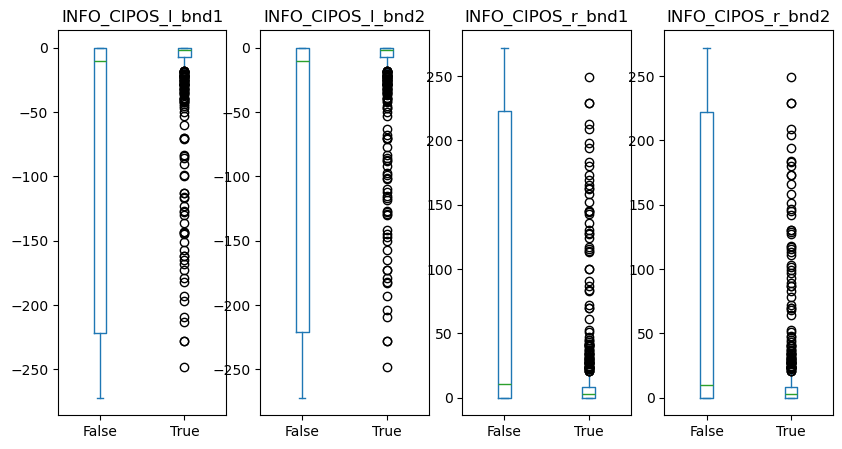

In [28]:
preds_vs_match_test = pd.concat([preds_vs_match, gridss_callset_bps['INFO_CIPOS_l_bnd1'], gridss_callset_bps['INFO_CIPOS_l_bnd2'], gridss_callset_bps['INFO_CIPOS_r_bnd1'], gridss_callset_bps['INFO_CIPOS_r_bnd2']], axis=1)
preds_vs_match_test.plot.box(by='is_in_truth', column=['INFO_CIPOS_l_bnd1', 'INFO_CIPOS_l_bnd2', 'INFO_CIPOS_r_bnd1', 'INFO_CIPOS_r_bnd2'], figsize=(10, 5))
# preds_vs_match_test.plot.box(by='is_in_truth', column=['gridss_QUAL'], figsize=(10, 5), ylim=(0, 5000))


<Axes: xlabel='False Positives', ylabel='True Positives'>

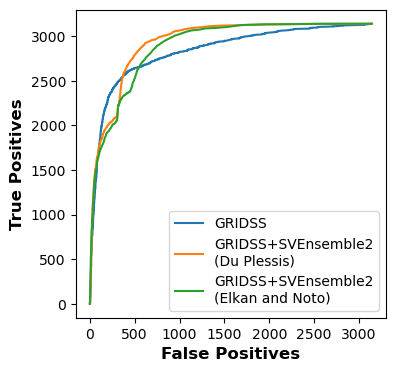

In [78]:
pred_dict = {
    'GRIDSS': preds_vs_match_plotting.gridss_QUAL,
    'GRIDSS+SVEnsemble2\n(Du Plessis)': preds_vs_match_plotting.y_duplessis,
    'GRIDSS+SVEnsemble2\n(Elkan and Noto)': preds_vs_match_plotting.y_enoto
}

plot_roc_curves(preds_vs_match_plotting.is_in_truth, pred_dict)

Text(0, 0.5, 'Precision')

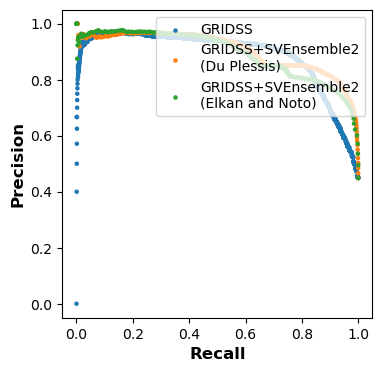

In [79]:
prec_gridss, rec_gridss, thresholds_gridss = precision_recall_curve(preds_vs_match_plotting.is_in_truth, preds_vs_match_plotting.gridss_QUAL, pos_label=True, drop_intermediate=True)
prec_duplessis, rec_duplessis, thresholds_duplessis = precision_recall_curve(preds_vs_match_plotting.is_in_truth, preds_vs_match_plotting.y_duplessis, pos_label=True, drop_intermediate=True)
prec_enoto, rec_enoto, thresholds_enoto = precision_recall_curve(preds_vs_match_plotting.is_in_truth, preds_vs_match_plotting.y_enoto, pos_label=True, drop_intermediate=True)

fig, ax = plt.subplots(figsize=(4, 4))

ax.scatter(rec_gridss, prec_gridss, label='GRIDSS', s=[5]*len(rec_gridss))
ax.scatter(rec_duplessis,prec_duplessis, label='GRIDSS+SVEnsemble2\n(Du Plessis)', s=[5]*len(rec_duplessis))
ax.scatter(rec_enoto, prec_enoto, label='GRIDSS+SVEnsemble2\n(Elkan and Noto)', s=[5]*len(rec_enoto))
ax.legend(loc=1)

plt.xlabel('Recall', size='large', weight=700)
plt.ylabel('Precision', size='large', weight=700)

# plot_precision_recall_curve(ref_duplessis.is_in_ref, ref_duplessis.y_duplessis)
# print(roc_auc_score((ref_duplessis.is_in_ref, ref_duplessis.y_duplessis)))

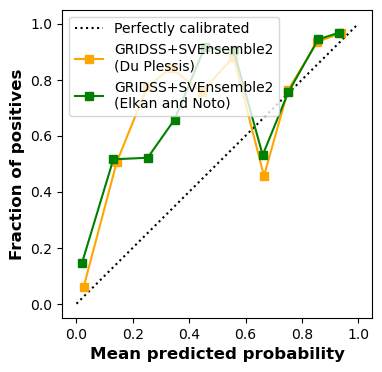

In [24]:
from sklearn.calibration import calibration_curve, CalibrationDisplay
prob_true, prob_pred = calibration_curve(preds_vs_match_plotting.is_in_truth, preds_vs_match_plotting.y_duplessis, n_bins=10)
disp_duplessis = CalibrationDisplay(prob_true, prob_pred, preds_vs_match_plotting.y_duplessis)

prob_true, prob_pred = calibration_curve(preds_vs_match_plotting.is_in_truth, preds_vs_match_plotting.y_enoto, n_bins=10)
disp_enoto = CalibrationDisplay(prob_true, prob_pred, preds_vs_match_plotting.y_enoto)

fig, ax = plt.subplots(figsize=(4, 4))
disp_duplessis.plot(ax=ax, label='GRIDSS+SVEnsemble2\n(Du Plessis)', color='orange')
disp_enoto.plot(ax=ax, label='GRIDSS+SVEnsemble2\n(Elkan and Noto)', color='green')

ax.legend(loc=2)

plt.xlabel('Mean predicted probability', size='large', weight=700)
plt.ylabel('Fraction of positives', size='large', weight=700)

plt.savefig('figs/calibcurve.duplessis_enoto.bps.png', bbox_inches='tight', dpi=300)

In [10]:
# gridss_callset_path = 'data/test_gridss_output.NA12878.annotated.vcf'
# gridss_callset_raw = vcfp.parse_vcf(gridss_callset_path, line_limit=None, skip_format=True)

In [11]:
# gridss_callset_raw = gridss_callset_raw[gridss_callset_raw['INFO_SIMPLE_TYPE'] == 'DEL']
# gridss_callset_raw

In [18]:
# gridss_callset_bps_pr = gridss_callset_bps[(gridss_callset_bps['INFO_END'] - gridss_callset_bps['POS'] > 1000) & (gridss_callset_bps['INFO_END'] - gridss_callset_bps['POS'] < 100000) & (gridss_callset_bps.FILTER_PASS)]
gridss_callset_bps_pr = gridss_callset_bps[(gridss_callset_bps.length > 50)]
gridss_callset_bps_pr = gridss_callset_bps[(gridss_callset_bps.FILTER_PASS)]
gridss_callset_bps_pr

,CHROM,POS,ID,REF,LALT,QUAL,FILTER_ASSEMBLY_BIAS,FILTER_ASSEMBLY_ONLY,FILTER_ASSEMBLY_TOO_FEW_READ,FILTER_ASSEMBLY_TOO_SHORT,FILTER_INSUFFICIENT_SUPPORT,FILTER_LOW_MAPQ,FILTER_LOW_QUAL,FILTER_NO_ASSEMBLY,FILTER_NO_RP,FILTER_NO_SR,FILTER_REF,FILTER_SINGLE_SUPPORT,FILTER_SMALL_EVENT,INFO_SVLEN,INFO_ASRP,INFO_ASSR,INFO_BA,INFO_BAQ,INFO_BASRP,INFO_BASSR,INFO_BEID,INFO_BENAMES,INFO_BPNAMES,INFO_CAS,INFO_CASQ,INFO_CQ,INFO_EVENT,INFO_HOMLEN,INFO_IC,INFO_IMPRECISE,INFO_INSRM,INFO_INSRMP,INFO_INSRMRC,INFO_INSRMRO,INFO_INSRMRT,INFO_INSTAXID,INFO_IQ,INFO_MQ,INFO_MQN,INFO_MQX,INFO_RF,INFO_RP,INFO_RPQ,INFO_RSI,INFO_SELF,INFO_SI,INFO_SR,INFO_SRQ,INFO_SVTYPE,INFO_VF,FILTER_PASS,INFO_END,RALT,CHR2,length,seq,ALT
150,chr1,1845834,gridss0fb_1029,N,A[chr1:1845864[,2725.38,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,64,0,0.00,0,0,"asm0-59592,asm0-7673,asm0-7683",0,0,0,0.00,2725.38,gridss0fb_1029,18,12,0,0,0,0,0,0,0,636.13,60.00,60.00,60.00,0,1,14.92,0,0,0,6,112.22,DEL,45,True,1845863,]chr1:1845833]C,chr1,30,A,<DEL>
156,chr1,2005917,gridss0fb_1143,N,C[chr1:2005937[,1697.97,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,44,0,0.00,0,0,"asm0-60790,asm0-8915",0,0,0,0.00,1697.97,gridss0fb_1143,17,10,0,0,0,0,0,0,0,422.84,60.00,60.00,60.00,0,0,0.00,0,0,0,0,0.00,DEL,34,True,2005936,]chr1:2005916]T,chr1,20,C,<DEL>
167,chr1,2295710,gridss0fb_1366,N,A[chr1:2295733[,2417.22,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,36,0,0.00,0,0,"asm0-10826,asm0-62527",0,0,0,0.00,2417.22,gridss0fb_1366,11,18,0,0,0,0,0,0,0,805.74,60.00,60.00,60.00,0,0,0.00,0,0,0,0,0.00,DEL,18,True,2295732,]chr1:2295709]C,chr1,23,A,<DEL>
170,chr1,2366971,gridss0fb_1430,N,A[chr1:2366983[,1112.77,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,23,0,0.00,0,0,"asm0-11256,asm0-62935",0,0,0,0.00,1112.77,gridss0fb_1430,28,10,0,0,0,0,0,0,0,354.91,60.00,60.00,60.00,0,0,0.00,0,0,0,0,0.00,DEL,13,True,2366982,]chr1:2366970]A,chr1,12,A,<DEL>
175,chr1,2557048,gridss0fb_1541,N,C[chr1:2557058[,1312.09,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,26,0,0.00,0,0,"asm0-12389,asm0-63962",0,0,0,0.00,1312.09,gridss0fb_1541,11,13,0,0,0,0,0,0,0,427.37,60.00,60.00,60.00,0,2,29.97,0,0,0,0,0.00,DEL,15,True,2557057,]chr1:2557047]T,chr1,10,C,<DEL>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
197151,chr1,91137361,gridss9fb_826,N,A[chr1:91137377[,3294.63,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,61,0,0.00,0,0,"asm9-48454,asm9-4901",0,0,0,0.00,3294.63,gridss9fb_826,26,27,0,0,0,0,0,0,0,1064.46,60.00,60.00,60.00,0,1,14.85,0,0,0,0,0.00,DEL,36,True,91137376,]chr1:91137360]A,chr1,16,A,<DEL>
197155,chr1,91159223,gridss9fb_848,N,G[chr1:91159506[,3834.57,0,0,0,0,0,0,0,0,0,0,0,0,0,0,94,68,0,0.00,0,0,"asm9-48562,asm9-5042",0,0,0,0.00,3804.31,gridss9fb_848,16,0,0,0,0,0,0,0,0,0.00,59.68,50.00,60.00,0,47,706.96,0,0,0,24,463.01,DEL,77,True,91159505,]chr1:91159222]A,chr1,283,G,<DEL>
197156,chr1,91168495,gridss9fb_853,N,G[chr1:91168519[,1570.37,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,42,0,0.00,0,0,"asm9-48599,asm9-5077",0,0,0,0.00,1585.25,gridss9fb_853,21,8,0,0,0,0,0,0,0,367.77,55.20,45.00,60.00,0,0,0.00,0,0,0,0,0.00,DEL,34,True,91168518,]chr1:91168494]T,chr1,24,G,<DEL>
197158,chr1,91169310,gridss9fb_859,N,C[chr1:91169348[,1959.35,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,70,0,0.00,0,0,"asm9-48592,asm9-5076",0,0,0,0.00,1959.35,gridss9fb_859,4,3,0,0,0,0,0,0,0,112.00,55.60,22.00,60.00,0,0,0.00,0,0,0,20,378.07,DEL,47,True,91169347,]chr1:91169309]G,chr1,38,C,<DEL>


In [19]:
gridss_callset_bps_pr = gridss_callset_bps_pr.rename(columns={
    'CHROM': 'Chromosome',
    'POS': 'Start',
    'INFO_END': 'End'
})
# gridss_callset_bps_pr = gridss_callset_bps_pr[(gridss_callset_bps_pr.End - gridss_callset_bps_pr.Start) > 50]
# gridss_callset_bps_pr = gridss_callset_bps_pr[gridss_callset_bps_pr['FILTER_PASS']]
# gridss_callset_bps_pr = gridss_callset_bps_pr[(gridss_callset_bps_pr.FILTER_PASS)]

gridss_callset_bps_pr

,Chromosome,Start,ID,REF,LALT,QUAL,FILTER_ASSEMBLY_BIAS,FILTER_ASSEMBLY_ONLY,FILTER_ASSEMBLY_TOO_FEW_READ,FILTER_ASSEMBLY_TOO_SHORT,FILTER_INSUFFICIENT_SUPPORT,FILTER_LOW_MAPQ,FILTER_LOW_QUAL,FILTER_NO_ASSEMBLY,FILTER_NO_RP,FILTER_NO_SR,FILTER_REF,FILTER_SINGLE_SUPPORT,FILTER_SMALL_EVENT,INFO_SVLEN,INFO_ASRP,INFO_ASSR,INFO_BA,INFO_BAQ,INFO_BASRP,INFO_BASSR,INFO_BEID,INFO_BENAMES,INFO_BPNAMES,INFO_CAS,INFO_CASQ,INFO_CQ,INFO_EVENT,INFO_HOMLEN,INFO_IC,INFO_IMPRECISE,INFO_INSRM,INFO_INSRMP,INFO_INSRMRC,INFO_INSRMRO,INFO_INSRMRT,INFO_INSTAXID,INFO_IQ,INFO_MQ,INFO_MQN,INFO_MQX,INFO_RF,INFO_RP,INFO_RPQ,INFO_RSI,INFO_SELF,INFO_SI,INFO_SR,INFO_SRQ,INFO_SVTYPE,INFO_VF,FILTER_PASS,End,RALT,CHR2,length,seq,ALT
150,chr1,1845834,gridss0fb_1029,N,A[chr1:1845864[,2725.38,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,64,0,0.00,0,0,"asm0-59592,asm0-7673,asm0-7683",0,0,0,0.00,2725.38,gridss0fb_1029,18,12,0,0,0,0,0,0,0,636.13,60.00,60.00,60.00,0,1,14.92,0,0,0,6,112.22,DEL,45,True,1845863,]chr1:1845833]C,chr1,30,A,<DEL>
156,chr1,2005917,gridss0fb_1143,N,C[chr1:2005937[,1697.97,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,44,0,0.00,0,0,"asm0-60790,asm0-8915",0,0,0,0.00,1697.97,gridss0fb_1143,17,10,0,0,0,0,0,0,0,422.84,60.00,60.00,60.00,0,0,0.00,0,0,0,0,0.00,DEL,34,True,2005936,]chr1:2005916]T,chr1,20,C,<DEL>
167,chr1,2295710,gridss0fb_1366,N,A[chr1:2295733[,2417.22,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,36,0,0.00,0,0,"asm0-10826,asm0-62527",0,0,0,0.00,2417.22,gridss0fb_1366,11,18,0,0,0,0,0,0,0,805.74,60.00,60.00,60.00,0,0,0.00,0,0,0,0,0.00,DEL,18,True,2295732,]chr1:2295709]C,chr1,23,A,<DEL>
170,chr1,2366971,gridss0fb_1430,N,A[chr1:2366983[,1112.77,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,23,0,0.00,0,0,"asm0-11256,asm0-62935",0,0,0,0.00,1112.77,gridss0fb_1430,28,10,0,0,0,0,0,0,0,354.91,60.00,60.00,60.00,0,0,0.00,0,0,0,0,0.00,DEL,13,True,2366982,]chr1:2366970]A,chr1,12,A,<DEL>
175,chr1,2557048,gridss0fb_1541,N,C[chr1:2557058[,1312.09,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,26,0,0.00,0,0,"asm0-12389,asm0-63962",0,0,0,0.00,1312.09,gridss0fb_1541,11,13,0,0,0,0,0,0,0,427.37,60.00,60.00,60.00,0,2,29.97,0,0,0,0,0.00,DEL,15,True,2557057,]chr1:2557047]T,chr1,10,C,<DEL>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
197151,chr1,91137361,gridss9fb_826,N,A[chr1:91137377[,3294.63,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,61,0,0.00,0,0,"asm9-48454,asm9-4901",0,0,0,0.00,3294.63,gridss9fb_826,26,27,0,0,0,0,0,0,0,1064.46,60.00,60.00,60.00,0,1,14.85,0,0,0,0,0.00,DEL,36,True,91137376,]chr1:91137360]A,chr1,16,A,<DEL>
197155,chr1,91159223,gridss9fb_848,N,G[chr1:91159506[,3834.57,0,0,0,0,0,0,0,0,0,0,0,0,0,0,94,68,0,0.00,0,0,"asm9-48562,asm9-5042",0,0,0,0.00,3804.31,gridss9fb_848,16,0,0,0,0,0,0,0,0,0.00,59.68,50.00,60.00,0,47,706.96,0,0,0,24,463.01,DEL,77,True,91159505,]chr1:91159222]A,chr1,283,G,<DEL>
197156,chr1,91168495,gridss9fb_853,N,G[chr1:91168519[,1570.37,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,42,0,0.00,0,0,"asm9-48599,asm9-5077",0,0,0,0.00,1585.25,gridss9fb_853,21,8,0,0,0,0,0,0,0,367.77,55.20,45.00,60.00,0,0,0.00,0,0,0,0,0.00,DEL,34,True,91168518,]chr1:91168494]T,chr1,24,G,<DEL>
197158,chr1,91169310,gridss9fb_859,N,C[chr1:91169348[,1959.35,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,70,0,0.00,0,0,"asm9-48592,asm9-5076",0,0,0,0.00,1959.35,gridss9fb_859,4,3,0,0,0,0,0,0,0,112.00,55.60,22.00,60.00,0,0,0.00,0,0,0,20,378.07,DEL,47,True,91169347,]chr1:91169309]G,chr1,38,C,<DEL>


In [54]:
overlapped_df_path = 'saved/gridss.overlapped_bnds.csv'
callset_overlapped_df = pd.read_csv(overlapped_df_path, index_col='ID')

In [55]:
# We need to join the PU callsets to corresponding training datasets
# Since the callsets do not contain coordinate and ID information
# They need to be concated to training data first (which has the ID info)
# And to the original caller callset to fetch the coordinate inf (using the added IDs)

y_duplessis = pd.read_csv('saved/y_duplessis_bnds.csv', index_col='index', names=['index', 'y_duplessis'], skiprows=1)

In [56]:
# We need to join the PU callsets to corresponding training datasets
# Since the callsets do not contain coordinate and ID information
# They need to be concated to training data first (which has the ID info)
# And to the original caller callset to fetch the coordinate inf (using the added IDs)
y_enoto = pd.read_csv('saved/y_enoto_bnds.csv', index_col='index', names=['index', 'y_enoto'], skiprows=1)

In [57]:
callset_overlapped_df_full = pd.concat([callset_overlapped_df.reset_index(), y_duplessis, y_enoto], axis=1)[['ID', 'y_duplessis', 'y_enoto']]

In [58]:
gridss_callset_copy = gridss_callset_raw.copy()
gridss_callset_copy = gridss_callset_copy.merge(callset_overlapped_df_full, how='left', on=['ID'])
gridss_callset_bps = bndc.bnd_to_event(gridss_callset_copy.iloc[:,], strict_matching=True, proba_cols=['y_duplessis', 'y_enoto'])
gridss_callset_bps.loc[:, 'y_duplessis_mean'] = np.mean(gridss_callset_bps[['y_duplessis_LEFT', 'y_duplessis']], axis=1)
gridss_callset_bps.loc[:, 'y_enoto_mean'] = np.mean(gridss_callset_bps[['y_enoto_LEFT', 'y_enoto']], axis=1)

105                                                     NaN
145                                                     NaN
149                                    GGGGGGGGGGGGGGCCCCCC
150                                                       A
154                                                       A
                                ...                        
197157    ACATGTCTACACGTGTACACATATGTCTATATACACATATACATAT...
197158                                                    C
197159    GTGTATATGCATTTATACGCATATATACATATATACACATATGTAT...
197160                                                    A
197167                                                    T
Name: seq, Length: 65220, dtype: object
       CHROM       POS              ID REF              LALT     QUAL  \
150     chr1   1845834  gridss0fb_1029   N   A[chr1:1845864[  2725.38   
154     chr1   1955040  gridss0fb_1102   N   A[chr1:1955058[   374.77   
156     chr1   2005917  gridss0fb_1143   N   C[chr1:2005937[  1697.97   
160     

In [25]:
duplessis_callset_pr = gridss_callset_bps_pr[['Chromosome', 'Start', 'End', 'ID']].merge(callset_overlapped_df, on='ID', how='left')
duplessis_callset_pr

,Chromosome,Start,End,ID,y_duplessis
0,chr1,1845834,1845863,gridss0fb_1029,NaN
1,chr1,2005917,2005936,gridss0fb_1143,NaN
2,chr1,2295710,2295732,gridss0fb_1366,NaN
3,chr1,2366971,2366982,gridss0fb_1430,NaN
4,chr1,2557048,2557057,gridss0fb_1541,NaN
...,...,...,...,...,...
21797,chr1,91137361,91137376,gridss9fb_826,NaN
21798,chr1,91159223,91159505,gridss9fb_848,NaN
21799,chr1,91168495,91168518,gridss9fb_853,NaN
21800,chr1,91169310,91169347,gridss9fb_859,NaN


In [ ]:
duplessis_callset_pr.loc[:, 'length'] = duplessis_callset_pr.End - duplessis_callset_pr.Start
duplessis_callset_pr = duplessis_callset_pr[duplessis_callset_pr.length > 50]
# duplessis_callset_pr[duplessis_callset_pr]

# duplessis_callset_pr = duplessis_callset_pr[(duplessis_callset_pr.length >= 1000) & (duplessis_callset_pr.length <= 100000)]


In [29]:
# We need to join the PU callsets to corresponding training datasets
# Since the callsets do not contain coordinate and ID information
# They need to be concated to training data first (which has the ID info)
# And to the original caller callset to fetch the coordinate inf (using the added IDs)
overlapped_df_path = 'saved/gridss_overlaps.tsv'
callset_overlapped_df = pd.read_csv(overlapped_df_path, sep='\t', index_col='ID')
y_duplessis = pd.read_csv('saved/y_duplessis.csv', index_col='index', names=['index', 'y_duplessis'], skiprows=1)
callset_overlapped_df = pd.concat([callset_overlapped_df.reset_index(), y_duplessis], axis=1)[['ID', 'y_duplessis']]

duplessis_callset_pr = gridss_callset_bps_pr[['Chromosome', 'Start', 'End', 'ID']].merge(callset_overlapped_df, on='ID', how='left')
duplessis_callset_pr.loc[:, 'length'] = duplessis_callset_pr.End - duplessis_callset_pr.Start
duplessis_callset_pr = duplessis_callset_pr[duplessis_callset_pr.length > 50]
# duplessis_callset_pr[duplessis_callset_pr]

# duplessis_callset_pr = duplessis_callset_pr[(duplessis_callset_pr.length >= 1000) & (duplessis_callset_pr.length <= 100000)]


In [30]:
duplessis_callset_pr

,Chromosome,Start,End,ID,y_duplessis,length
6,chr1,2634712,2635163,gridss0fb_1581,0.264,451
9,chr1,2994979,2995292,gridss0fb_1864,0.744,313
10,chr1,3002469,3002803,gridss0fb_1870,0.292,334
45,chr1,934104,934830,gridss0fb_404,0.058,726
90,chr16,25328790,25331807,gridss100fb_1299,0.944,3017
...,...,...,...,...,...,...
21746,chr1,92215797,92215848,gridss9fb_1694,0.814,51
21759,chr1,93822818,93825701,gridss9fb_2933,0.934,2883
21768,chr1,95224962,95225280,gridss9fb_3914,0.892,318
21780,chr1,98714388,98714494,gridss9fb_6268,0.870,106


In [31]:
overlapped_df_path = 'saved/gridss_overlaps.tsv'
callset_overlapped_df = pd.read_csv(overlapped_df_path, sep='\t', index_col='ID')
y_enoto = pd.read_csv('saved/y_enoto.csv', index_col='index', names=['index', 'y_enoto'], skiprows=1)
callset_overlapped_df = pd.concat([callset_overlapped_df.reset_index(), y_enoto], axis=1)[['ID', 'y_enoto']]

enoto_callset_pr = gridss_callset_bps_pr[['Chromosome', 'Start', 'End', 'ID']].merge(callset_overlapped_df, on='ID', how='left')
enoto_callset_pr.loc[:, 'length'] = enoto_callset_pr.End - enoto_callset_pr.Start
enoto_callset_pr = enoto_callset_pr[enoto_callset_pr.length > 50]

# enoto_callset_pr = enoto_callset_pr[(enoto_callset_pr.length >= 1000) & (enoto_callset_pr.length <= 100000)]

In [32]:
# What I have: 
# - GRIDSS callset (for now DELs only)
# - 2 PU callsets (Trained to detect DELs)
#   
# - High confidence callset (DELs only)
# - gnomad data
#
# What I want:
# - full join of all except gnomad
#   with overlaps reported between high confidence and all other callsets
#
# How to do it:
# 1. Convert all to prs
# 2. Left-join each pr to high confidence
#    In the joined datasets there may be multiple overlaps
# 3. To resolve them, filter by overlap fraction (>80% overlap)
#    Variants with >80% overlap are considered the same, others are considered different.
#    Report all the joined variants as lists.
# 4. Concatenate the non-joined variants as if they do not overlap

In [59]:
def full_callset_join(ref_df, call_df):

    try:
        ref_df_pr = pr.PyRanges(ref_df)
    except Exception as e:
        if str(e) == 'Object is already a PyRange.':
            ref_df_pr = ref_df
            pass
        else:
            raise

    try:
        call_df_pr = pr.PyRanges(call_df)
    except Exception as e:
        if str(e) == 'Object is already a PyRange.':
            call_df_pr = call_df
            pass
        else:
            raise
    
    ref_call_pr = ref_df_pr.join(call_df_pr, report_overlap=True)
    
    ref_call_pr = ref_call_pr.df.reset_index(drop=True)
    ref_call_pr.loc[:, 'overlap_frac'] = ref_call_pr.Overlap * 2 / (ref_call_pr.End - ref_call_pr.Start + ref_call_pr.End_b - ref_call_pr.Start_b)
    ref_call_pr = ref_call_pr[ref_call_pr.overlap_frac > 0.8].sort_values(by='overlap_frac', ascending=False).drop_duplicates(subset=['ID'], keep='first').drop_duplicates(subset=['ID_b'], keep='first')
    
    # overlapping_ids_gridss_ref = ref_gridss_pr[ref_gridss_pr.overlap_frac > 0.8][['ID']]
    # overlapping_ids_gridss_callset = ref_gridss_pr[ref_gridss_pr.overlap_frac > 0.8][['ID_b']]
    
    overlapping_ids_ref = ref_call_pr['ID']
    overlapping_ids_call = ref_call_pr['ID_b']
    
    ref_df_pr_nonoverlapping = ref_df_pr.df[~ref_df_pr.df['ID'].isin(overlapping_ids_ref)].reset_index(drop=True)
    call_df_pr_nonoverlapping = call_df_pr.df[~call_df_pr.df['ID'].isin(overlapping_ids_call)].reset_index(drop=True).rename(columns={
        'ID': 'ID_b'
    })
    call_df_pr_nonoverlapping.loc[:, 'is_in_ref'] = False
    
    ref_call_pr = pd.concat([ref_call_pr, ref_df_pr_nonoverlapping, call_df_pr_nonoverlapping])
    
    # ref_call_pr.loc[:, 'ref_overlap_detected'] = (ref_call_pr.overlap_frac > 0.8) & (~ref_call_pr.overlap_frac.isna())
    # ref_call_pr.loc[:, 'is_in_ref'] = (~ref_call_pr.is_in_ref.isna()).astype(bool)

    return ref_call_pr

In [34]:
# ref_df=ref_df_pr
# call_df=gridss_callset_bps_pr

# try:
#     ref_df_pr = pr.PyRanges(ref_df)
# except Exception as e:
#     if str(e) == 'Object is already a PyRange.':
#         ref_df_pr = ref_df
#         pass
#     else:
#         raise

# try:
#     call_df_pr = pr.PyRanges(call_df)
# except Exception as e:
#     if str(e) == 'Object is already a PyRange.':
#         call_df_pr = call_df
#         pass
#     else:
#         raise

# ref_call_pr = ref_df_pr.join(call_df_pr, report_overlap=True)
# ref_call_pr = ref_call_pr.df.reset_index(drop=True)
# ref_call_pr.loc[:, 'overlap_frac'] = ref_call_pr.Overlap * 2 / (ref_call_pr.End - ref_call_pr.Start + ref_call_pr.End_b - ref_call_pr.Start_b)

# # ref_call_pr = ref_call_pr[ref_call_pr.overlap_frac > 0.8].sort_values(by='overlap_frac', ascending=False).drop_duplicates(subset=['ID'], keep='first').drop_duplicates(subset=['ID_b'], keep='first')
# ref_call_pr = ref_call_pr.sort_values(by='overlap_frac', ascending=False)#.drop_duplicates(subset=['ID'], keep='first').drop_duplicates(subset=['ID_b'], keep='first')
# ref_call_pr = ref_call_pr[ref_call_pr.overlap_frac > 0.8]

# # # overlapping_ids_gridss_ref = ref_gridss_pr[ref_gridss_pr.overlap_frac > 0.8][['ID']]
# # # overlapping_ids_gridss_callset = ref_gridss_pr[ref_gridss_pr.overlap_frac > 0.8][['ID_b']]

# # overlapping_ids_ref = ref_call_pr['ID']
# # overlapping_ids_call = ref_call_pr['ID_b']

# # ref_df_pr_nonoverlapping = ref_df_pr.df[~ref_df_pr.df['ID'].isin(overlapping_ids_ref)].reset_index(drop=True)
# # call_df_pr_nonoverlapping = call_df_pr.df[~call_df_pr.df['ID'].isin(overlapping_ids_call)].reset_index(drop=True).rename(columns={
# #     'ID': 'ID_b'
# # })
# # call_df_pr_nonoverlapping.loc[:, 'is_in_ref'] = False

# # ref_call_pr = pd.concat([ref_call_pr, ref_df_pr_nonoverlapping, call_df_pr_nonoverlapping])

# ref_call_pr.loc[:, 'length_b'] = ref_call_pr['End_b'] - ref_call_pr['Start_b']

# ref_call_pr[['Start', 'End', 'length', 'Start_b', 'End_b', 'length_b', 'Overlap', 'FILTER_PASS']]

# ref_call_pr.value_counts('FILTER_PASS')


In [35]:
ref_gridss = full_callset_join(ref_df=ref_df_pr, call_df=gridss_callset_bps_pr)
ref_gridss_h = full_callset_join(ref_df=ref_df_pr, call_df=gridss_callset_bps_pr[gridss_callset_bps_pr.FILTER_PASS.astype(bool)])
ref_duplessis = full_callset_join(ref_df=ref_df_pr, call_df=duplessis_callset_pr)
ref_enoto = full_callset_join(ref_df=ref_df_pr, call_df=enoto_callset_pr)

In [18]:
ref_gridss = full_callset_join(ref_df=ref_df_pr, call_df=gridss_callset_raw)

,Chromosome,Start,End,ALT,length,is_in_ref,ID,Start_b,ID_b,REF,LALT,QUAL,FILTER_ASSEMBLY_BIAS,FILTER_ASSEMBLY_ONLY,FILTER_ASSEMBLY_TOO_FEW_READ,FILTER_ASSEMBLY_TOO_SHORT,FILTER_INSUFFICIENT_SUPPORT,FILTER_LOW_MAPQ,FILTER_LOW_QUAL,FILTER_NO_ASSEMBLY,FILTER_NO_RP,FILTER_NO_SR,FILTER_REF,FILTER_SINGLE_SUPPORT,FILTER_SMALL_EVENT,INFO_SVLEN,INFO_ASRP,INFO_ASSR,INFO_BA,INFO_BAQ,INFO_BASRP,INFO_BASSR,INFO_BEID,INFO_BENAMES,INFO_BPNAMES,INFO_CAS,INFO_CASQ,INFO_CQ,INFO_EVENT,INFO_HOMLEN,INFO_IC,INFO_IMPRECISE,INFO_INSRM,INFO_INSRMP,INFO_INSRMRC,INFO_INSRMRO,INFO_INSRMRT,INFO_INSTAXID,INFO_IQ,INFO_MQ,INFO_MQN,INFO_MQX,INFO_RF,INFO_RP,INFO_RPQ,INFO_RSI,INFO_SELF,INFO_SI,INFO_SR,INFO_SRQ,INFO_SVTYPE,INFO_VF,FILTER_PASS,End_b,RALT,CHR2,length_b,seq,ALT_b,Overlap,overlap_frac
1989,chr10,95447298,95448270,DEL,972,True,chr10:95447298-95448270,95447298.0,gridss34fb_3475,N,G[chr10:95448271[,2345.42,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,58,40,0,0.00,0,0,"asm34-23039,asm34-23047,asm34-72837",0.0,0.0,1,30.31,2345.42,gridss34fb_3475,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,59.25,33.00,60.00,0.0,29,439.56,0.0,0.0,0.0,12,249.60,DEL,44,True,95448270.0,]chr10:95447297]T,chr10,973.0,G,<DEL>,972.0,1.0
270,chr1,217909322,217909555,DEL,233,True,chr1:217909322-217909555,217909322.0,gridss21fb_5759,N,T[chr1:217909556[,885.30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12,21,0,0.00,0,0,"asm21-35204,asm21-78229,asm21-78231",0.0,0.0,0,0.00,885.30,gridss21fb_5759,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,60.00,60.00,60.00,0.0,10,150.55,0.0,0.0,0.0,7,145.85,DEL,24,True,217909555.0,]chr1:217909321]T,chr1,234.0,T,<DEL>,233.0,1.0
2714,chr18,26991657,26992377,DEL,720,True,chr18:26991657-26992377,26991657.0,gridss117fb_4155,N,A[chr18:26992378[,1329.84,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31,25,0,0.00,0,0,"asm117-29615,asm117-68407",0.0,0.0,0,0.00,1329.84,gridss117fb_4155,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,60.00,60.00,60.00,0.0,18,272.83,0.0,0.0,0.0,6,121.67,DEL,26,True,26992377.0,]chr18:26991656]T,chr18,721.0,A,<DEL>,720.0,1.0
261,chr1,194548478,194548737,DEL,259,True,chr1:194548478-194548737,194548478.0,gridss19fb_3259,N,C[chr1:194548738[,3765.53,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,92,64,0,0.00,0,0,"asm19-17703,asm19-56434",0.0,0.0,0,0.00,3744.48,gridss19fb_3259,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,59.60,37.00,60.00,0.0,48,720.32,0.0,0.0,0.0,20,415.54,DEL,84,True,194548737.0,]chr1:194548477]A,chr1,260.0,C,<DEL>,259.0,1.0
367,chr2,40219807,40219933,DEL,126,True,chr2:40219807-40219933,40219807.0,gridss133fb_54,N,C[chr2:40219934[,863.66,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2,30,0,0.00,0,0,"asm133-283,asm133-46962,asm133-46969",0.0,0.0,0,0.00,863.66,gridss133fb_54,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,60.00,60.00,60.00,0.0,3,44.86,0.0,0.0,0.0,10,205.84,DEL,23,True,40219933.0,]chr2:40219806]T,chr2,127.0,C,<DEL>,126.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7020,chrY,23364741,23742759,DEL,378018,True,chrY:23364741-23742759,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7021,chrY,23821643,24084364,DEL,262721,True,chrY:23821643-24084364,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7022,chrY,24164942,24856589,DEL,691647,True,chrY:24164942-24856589,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [19]:
ref_gridss[ref_gridss['is_in_ref'] & (ref_gridss['overlap_frac'] > 0.8)]

,Chromosome,Start,End,ALT,length,is_in_ref,ID,Start_b,ID_b,REF,LALT,QUAL,FILTER_ASSEMBLY_BIAS,FILTER_ASSEMBLY_ONLY,FILTER_ASSEMBLY_TOO_FEW_READ,FILTER_ASSEMBLY_TOO_SHORT,FILTER_INSUFFICIENT_SUPPORT,FILTER_LOW_MAPQ,FILTER_LOW_QUAL,FILTER_NO_ASSEMBLY,FILTER_NO_RP,FILTER_NO_SR,FILTER_REF,FILTER_SINGLE_SUPPORT,FILTER_SMALL_EVENT,INFO_SVLEN,INFO_ASRP,INFO_ASSR,INFO_BA,INFO_BAQ,INFO_BASRP,INFO_BASSR,INFO_BEID,INFO_BENAMES,INFO_BPNAMES,INFO_CAS,INFO_CASQ,INFO_CQ,INFO_EVENT,INFO_HOMLEN,INFO_IC,INFO_IMPRECISE,INFO_INSRM,INFO_INSRMP,INFO_INSRMRC,INFO_INSRMRO,INFO_INSRMRT,INFO_INSTAXID,INFO_IQ,INFO_MQ,INFO_MQN,INFO_MQX,INFO_RF,INFO_RP,INFO_RPQ,INFO_RSI,INFO_SELF,INFO_SI,INFO_SR,INFO_SRQ,INFO_SVTYPE,INFO_VF,FILTER_PASS,End_b,RALT,CHR2,length_b,seq,ALT_b,Overlap,overlap_frac
1989,chr10,95447298,95448270,DEL,972,True,chr10:95447298-95448270,95447298.0,gridss34fb_3475,N,G[chr10:95448271[,2345.42,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,58,40,0,0.00,0,0,"asm34-23039,asm34-23047,asm34-72837",0.0,0.0,1,30.31,2345.42,gridss34fb_3475,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,59.25,33.00,60.00,0.0,29,439.56,0.0,0.0,0.0,12,249.60,DEL,44,True,95448270.0,]chr10:95447297]T,chr10,973.0,G,<DEL>,972.0,1.000000
270,chr1,217909322,217909555,DEL,233,True,chr1:217909322-217909555,217909322.0,gridss21fb_5759,N,T[chr1:217909556[,885.30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12,21,0,0.00,0,0,"asm21-35204,asm21-78229,asm21-78231",0.0,0.0,0,0.00,885.30,gridss21fb_5759,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,60.00,60.00,60.00,0.0,10,150.55,0.0,0.0,0.0,7,145.85,DEL,24,True,217909555.0,]chr1:217909321]T,chr1,234.0,T,<DEL>,233.0,1.000000
2714,chr18,26991657,26992377,DEL,720,True,chr18:26991657-26992377,26991657.0,gridss117fb_4155,N,A[chr18:26992378[,1329.84,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31,25,0,0.00,0,0,"asm117-29615,asm117-68407",0.0,0.0,0,0.00,1329.84,gridss117fb_4155,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,60.00,60.00,60.00,0.0,18,272.83,0.0,0.0,0.0,6,121.67,DEL,26,True,26992377.0,]chr18:26991656]T,chr18,721.0,A,<DEL>,720.0,1.000000
261,chr1,194548478,194548737,DEL,259,True,chr1:194548478-194548737,194548478.0,gridss19fb_3259,N,C[chr1:194548738[,3765.53,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,92,64,0,0.00,0,0,"asm19-17703,asm19-56434",0.0,0.0,0,0.00,3744.48,gridss19fb_3259,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,59.60,37.00,60.00,0.0,48,720.32,0.0,0.0,0.0,20,415.54,DEL,84,True,194548737.0,]chr1:194548477]A,chr1,260.0,C,<DEL>,259.0,1.000000
367,chr2,40219807,40219933,DEL,126,True,chr2:40219807-40219933,40219807.0,gridss133fb_54,N,C[chr2:40219934[,863.66,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2,30,0,0.00,0,0,"asm133-283,asm133-46962,asm133-46969",0.0,0.0,0,0.00,863.66,gridss133fb_54,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,60.00,60.00,60.00,0.0,3,44.86,0.0,0.0,0.0,10,205.84,DEL,23,True,40219933.0,]chr2:40219806]T,chr2,127.0,C,<DEL>,126.0,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2805,chr19,23472368,23472429,DEL,61,True,chr19:23472368-23472429,23472381.0,gridss125fb_3245,N,A[chr19:23472438[,875.02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,35,0,0.00,0,0,"asm125-23480,asm125-59449",0.0,0.0,0,0.00,875.02,gridss125fb_3245,16,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,56.20,30.00,60.00,0.0,0,0.00,0.0,0.0,0.0,13,242.66,DEL,22,True,23472437.0,]chr19:23472380]T,chr19,57.0,A,<DEL>,48.0,0.820513
650,chr3,82908099,82908475,DEL,376,True,chr3:82908099-82908475,82908173.0,gridss177fb_5100,N,T[chr3:82908433[,1312.88,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,40,12,0,0.00,0,0,"asm177-31114,asm177-69781",0.0,0.0,0,0.00,1312.88,gridss177fb_5100,10,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,58.74,40.00,60.00,0.0,25,375.05,0.0,0.0,0.0,0,0.00,DEL,36,Tru

In [36]:
# ref_gridss[ref_gridss['overlap_frac'] > 0.8]

In [37]:
ref_gridss = ref_gridss[~ref_gridss.QUAL.isna()]
ref_gridss_h = ref_gridss_h[~ref_gridss_h.QUAL.isna()]
ref_duplessis = ref_duplessis[~ref_duplessis.y_duplessis.isna()]
ref_enoto = ref_enoto[~ref_enoto.y_enoto.isna()]

In [38]:
ref_gridss[ref_gridss.FILTER_PASS]

,Chromosome,Start,End,ALT,length,is_in_ref,ID,Start_b,ID_b,REF,LALT,QUAL,FILTER_ASSEMBLY_BIAS,FILTER_ASSEMBLY_ONLY,FILTER_ASSEMBLY_TOO_FEW_READ,FILTER_ASSEMBLY_TOO_SHORT,FILTER_INSUFFICIENT_SUPPORT,FILTER_LOW_MAPQ,FILTER_LOW_QUAL,FILTER_NO_ASSEMBLY,FILTER_NO_RP,FILTER_NO_SR,FILTER_REF,FILTER_SINGLE_SUPPORT,FILTER_SMALL_EVENT,INFO_SVLEN,INFO_ASRP,INFO_ASSR,INFO_BA,INFO_BAQ,INFO_BASRP,INFO_BASSR,INFO_BEID,INFO_BENAMES,INFO_BPNAMES,INFO_CAS,INFO_CASQ,INFO_CQ,INFO_EVENT,INFO_HOMLEN,INFO_IC,INFO_IMPRECISE,INFO_INSRM,INFO_INSRMP,INFO_INSRMRC,INFO_INSRMRO,INFO_INSRMRT,INFO_INSTAXID,INFO_IQ,INFO_MQ,INFO_MQN,INFO_MQX,INFO_RF,INFO_RP,INFO_RPQ,INFO_RSI,INFO_SELF,INFO_SI,INFO_SR,INFO_SRQ,INFO_SVTYPE,INFO_VF,FILTER_PASS,End_b,RALT,CHR2,length_b,seq,ALT_b,Overlap,overlap_frac
1989,chr10,95447298,95448270,DEL,972,True,chr10:95447298-95448270,95447298.0,gridss34fb_3475,N,G[chr10:95448271[,2345.42,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,58,40,0,0.00,0,0,"asm34-23039,asm34-23047,asm34-72837",0.0,0.0,1,30.31,2345.42,gridss34fb_3475,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,59.25,33.00,60.00,0.0,29,439.56,0.0,0.0,0.0,12,249.60,DEL,44,True,95448270.0,]chr10:95447297]T,chr10,973.0,G,<DEL>,972.0,1.0
270,chr1,217909322,217909555,DEL,233,True,chr1:217909322-217909555,217909322.0,gridss21fb_5759,N,T[chr1:217909556[,885.30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12,21,0,0.00,0,0,"asm21-35204,asm21-78229,asm21-78231",0.0,0.0,0,0.00,885.30,gridss21fb_5759,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,60.00,60.00,60.00,0.0,10,150.55,0.0,0.0,0.0,7,145.85,DEL,24,True,217909555.0,]chr1:217909321]T,chr1,234.0,T,<DEL>,233.0,1.0
2714,chr18,26991657,26992377,DEL,720,True,chr18:26991657-26992377,26991657.0,gridss117fb_4155,N,A[chr18:26992378[,1329.84,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31,25,0,0.00,0,0,"asm117-29615,asm117-68407",0.0,0.0,0,0.00,1329.84,gridss117fb_4155,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,60.00,60.00,60.00,0.0,18,272.83,0.0,0.0,0.0,6,121.67,DEL,26,True,26992377.0,]chr18:26991656]T,chr18,721.0,A,<DEL>,720.0,1.0
261,chr1,194548478,194548737,DEL,259,True,chr1:194548478-194548737,194548478.0,gridss19fb_3259,N,C[chr1:194548738[,3765.53,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,92,64,0,0.00,0,0,"asm19-17703,asm19-56434",0.0,0.0,0,0.00,3744.48,gridss19fb_3259,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,59.60,37.00,60.00,0.0,48,720.32,0.0,0.0,0.0,20,415.54,DEL,84,True,194548737.0,]chr1:194548477]A,chr1,260.0,C,<DEL>,259.0,1.0
367,chr2,40219807,40219933,DEL,126,True,chr2:40219807-40219933,40219807.0,gridss133fb_54,N,C[chr2:40219934[,863.66,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2,30,0,0.00,0,0,"asm133-283,asm133-46962,asm133-46969",0.0,0.0,0,0.00,863.66,gridss133fb_54,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,60.00,60.00,60.00,0.0,3,44.86,0.0,0.0,0.0,10,205.84,DEL,23,True,40219933.0,]chr2:40219806]T,chr2,127.0,C,<DEL>,126.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19779,chr22,47009482,47009495,<DEL>,14,False,NaN,NaN,gridss169fb_640,N,A[chr22:47009496[,2207.50,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,43,0,0.00,0,0,"asm169-49615,asm169-5196",0.0,0.0,0,0.00,2207.50,gridss169fb_640,8,19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,708.98,60.00,60.00,60.00,0.0,0,0.00,0.0,0.0,0.0,0,0.00,DEL,23,True,NaN,]chr22:47009481]C,chr22,NaN,A,NaN,NaN,NaN
19780,chr22,47174616,47174631,<DEL>,16,False,NaN,NaN,gridss169fb_737,N,C[chr22:47174632[,1008.65,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,20,0,0.00,0,0,"asm169-50253,asm169-5910",0.0,0.0,0,0.00,1008.65,gridss169fb_737,17,8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,314.51,60.00,60.00,60.00,0.0,0,0.00,0.0,0.0,0.0,0,0.00,DEL,12,True,NaN,]chr22:47174615]G,chr22,NaN,C,NaN,NaN,NaN
19781,chr22,47254296,47254307,<DEL>,12,Fals

In [39]:
ref_gridss.loc[ref_gridss.QUAL.isna(), 'QUAL'] = -1
ref_gridss_h.loc[ref_gridss_h.QUAL.isna(), 'QUAL'] = -1
ref_duplessis.loc[ref_duplessis.y_duplessis.isna(), 'y_duplessis'] = -1
ref_enoto.loc[ref_enoto.y_enoto.isna(), 'y_enoto'] = -1
# ref_gridss_h = ref_gridss_h[~ref_gridss_h.QUAL.isna()]
# ref_duplessis = ref_duplessis[~ref_duplessis.y_duplessis.isna()]
# ref_enoto = ref_enoto[~ref_enoto.y_enoto.isna()]

<Axes: title={'center': 'logQUAL'}, xlabel='is_in_ref'>

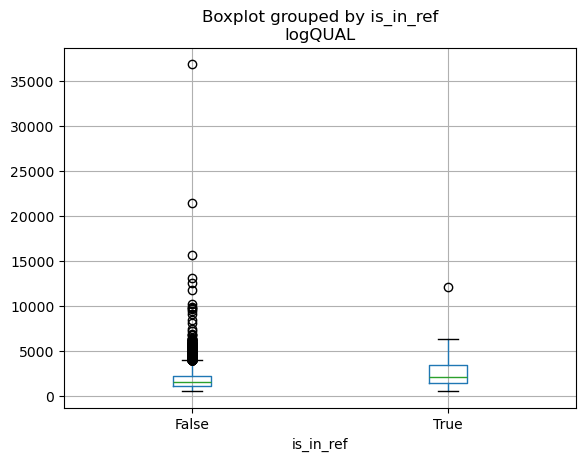

In [40]:
ref_gridss.loc[:, 'logQUAL'] = ref_gridss.QUAL
ref_gridss.boxplot(column='logQUAL', by='is_in_ref')

In [41]:
# ref_gridss = ref_gridss[
#     ((ref_gridss.End - ref_gridss.Start) > 50) & (((ref_gridss.End_b - ref_gridss.Start_b) > 50) | (ref_gridss.End_b.isna()))
# ]
# ref_duplessis = ref_duplessis[(((ref_duplessis.End - ref_duplessis.Start) > 50) & ((ref_duplessis.End_b - ref_duplessis.Start_b) > 50)) | ref_duplessis.End.isna()  | ref_duplessis.Start.isna() | ref_duplessis.End_b.isna() | ref_duplessis.Start_b.isna()]

In [42]:
test_df = pd.concat([ref_duplessis.is_in_ref, ref_duplessis.y_duplessis, ref_duplessis.ID], axis=1)

In [43]:
test_df.loc[:, 'ID_present'] = ~test_df.ID.isna()

In [44]:
test_df

,is_in_ref,y_duplessis,ID,ID_present
2244,True,0.936,chr18:26991657-26992377,True
1028,True,0.248,chr6:32708797-32709253,True
516,True,0.610,chr3:110025150-110025217,True
2274,True,0.872,chr18:65329610-65329690,True
1976,True,0.972,chr13:85362566-85363496,True
...,...,...,...,...
157,False,0.952,NaN,False
158,False,0.930,NaN,False
159,False,0.744,NaN,False
160,False,0.902,NaN,False


<Axes: title={'center': 'y_duplessis'}, xlabel='is_in_ref'>

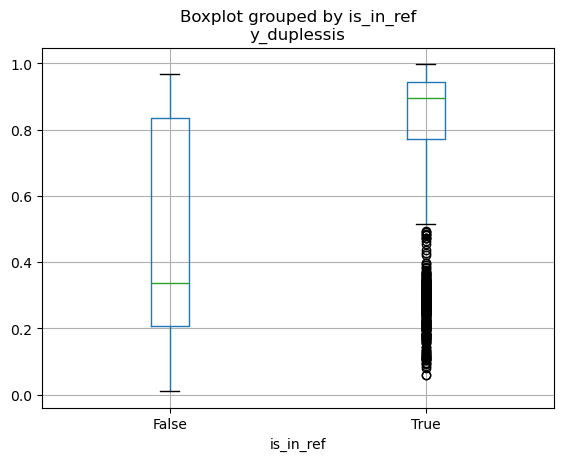

In [45]:
test_df.boxplot(column='y_duplessis', by='is_in_ref')

In [46]:
test_df.groupby('is_in_ref').describe()

y_duplessis                                                         
                count      mean       std    min     25%    50%     75%    max
is_in_ref                                                                     
False           162.0  0.489235  0.317041  0.010  0.2065  0.337  0.8335  0.968
True           1997.0  0.781030  0.249990  0.058  0.7700  0.896  0.9420  0.998

In [47]:
def plot_roc_curve(true_y, y_prob):
    """
    plots the roc curve based of the probabilities
    """

    fpr, tpr, thresholds = roc_curve(true_y, y_prob, pos_label=True)
    plt.plot(fpr, tpr)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')

In [48]:
roc_auc_score(ref_duplessis.is_in_ref, ref_duplessis.y_duplessis)

np.float64(0.7868330273187558)

In [49]:
print(
    sum(ref_gridss.is_in_ref),
    sum(ref_duplessis.is_in_ref),
    sum(ref_enoto.is_in_ref)
)

2018 1997 1997


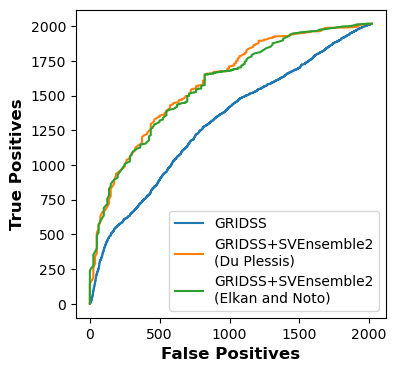

In [50]:
fpr_gridss, tpr_gridss, thresholds_gridss = roc_curve(ref_gridss.is_in_ref, ref_gridss.QUAL, pos_label=True)
tpnum_gridss = tpr_gridss*sum(ref_gridss.is_in_ref)
fpnum_gridss = fpr_gridss*sum(ref_gridss.is_in_ref)
fpr_duplessis, tpr_duplessis, thresholds_duplessis = roc_curve(ref_duplessis.is_in_ref, ref_duplessis.y_duplessis, pos_label=True)
tpnum_duplessis = tpr_duplessis*sum(ref_gridss.is_in_ref)
fpnum_duplessis = fpr_duplessis*sum(ref_gridss.is_in_ref)
fpr_enoto, tpr_enoto, thresholds_enoto = roc_curve(ref_enoto.is_in_ref, ref_enoto.y_enoto, pos_label=True)
tpnum_enoto = tpr_enoto*sum(ref_gridss.is_in_ref)
fpnum_enoto = fpr_enoto*sum(ref_gridss.is_in_ref)

fig, ax = plt.subplots(figsize=(4,4))

ax.plot(fpnum_gridss, tpnum_gridss, label='GRIDSS')
ax.plot(fpnum_duplessis, tpnum_duplessis, label='GRIDSS+SVEnsemble2\n(Du Plessis)')
ax.plot(fpnum_enoto, tpnum_enoto, label='GRIDSS+SVEnsemble2\n(Elkan and Noto)')
# ax.plot(fpr_gridss, tpr_gridss, label='GRIDSS')
# ax.plot(fpr_duplessis, tpr_duplessis, label='GRIDSS+SVEnsemble2\n(Du Plessis)')
# ax.plot(fpr_enoto, tpr_enoto, label='GRIDSS+SVEnsemble2\n(Elkan and Noto)')
ax.legend(loc=4)

plt.xlabel('False Positives', size='large', weight=700)
plt.ylabel('True Positives', size='large', weight=700)

plt.savefig('figs/roc_full.png', bbox_inches='tight', dpi=300)

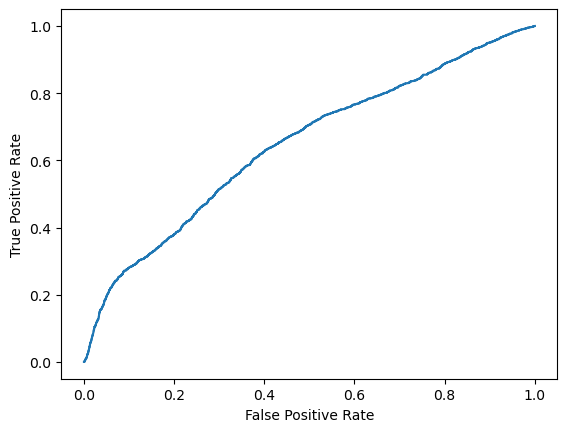

In [88]:
plot_roc_curve(ref_gridss_h.is_in_ref, ref_gridss_h.QUAL)

In [89]:
def plot_precision_recall_curve(true_y, y_prob):
    """
    plots the roc curve based of the probabilities
    """

    prec, rec, thresholds = precision_recall_curve(true_y, y_prob)
    plt.plot(prec, rec)
    plt.xlabel('Recall')
    plt.ylabel('Precision')

Text(0, 0.5, 'Precision')

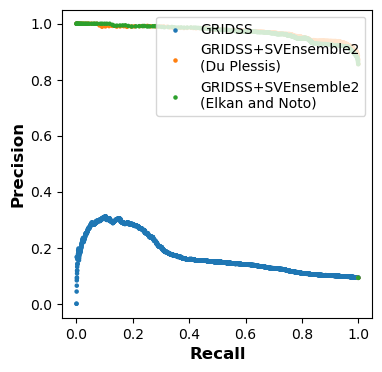

In [90]:
prec_gridss, rec_gridss, thresholds_gridss = precision_recall_curve(ref_gridss.is_in_ref, ref_gridss.QUAL, pos_label=True, drop_intermediate=True)
# tp_gridss = prec_gridss * (ref_gridss.shape[0])
prec_duplessis, rec_duplessis, thresholds_duplessis = precision_recall_curve(ref_duplessis.is_in_ref, ref_duplessis.y_duplessis, pos_label=True, drop_intermediate=True)
prec_enoto, rec_enoto, thresholds_enoto = precision_recall_curve(ref_enoto.is_in_ref, ref_enoto.y_enoto, pos_label=True, drop_intermediate=True)

fig, ax = plt.subplots(figsize=(4, 4))

ax.scatter(rec_gridss, prec_gridss, label='GRIDSS', s=[5]*len(rec_gridss))
ax.scatter(rec_duplessis,prec_duplessis, label='GRIDSS+SVEnsemble2\n(Du Plessis)', s=[5]*len(rec_duplessis))
ax.scatter(rec_enoto, prec_enoto, label='GRIDSS+SVEnsemble2\n(Elkan and Noto)', s=[5]*len(rec_enoto))
ax.legend(loc=1)

plt.xlabel('Recall', size='large', weight=700)
plt.ylabel('Precision', size='large', weight=700)

# plot_precision_recall_curve(ref_duplessis.is_in_ref, ref_duplessis.y_duplessis)
# print(roc_auc_score((ref_duplessis.is_in_ref, ref_duplessis.y_duplessis)))

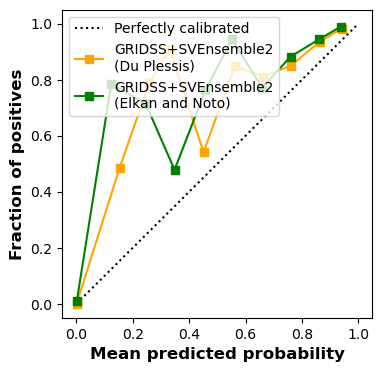

In [64]:
from sklearn.calibration import calibration_curve, CalibrationDisplay
prob_true, prob_pred = calibration_curve(ref_duplessis.is_in_ref, ref_duplessis.y_duplessis, n_bins=10)
disp_duplessis = CalibrationDisplay(prob_true, prob_pred, ref_duplessis.y_duplessis)

prob_true, prob_pred = calibration_curve(ref_enoto.is_in_ref, ref_enoto.y_enoto, n_bins=10)
disp_enoto = CalibrationDisplay(prob_true, prob_pred, ref_enoto.y_enoto)

fig, ax = plt.subplots(figsize=(4, 4))
disp_duplessis.plot(ax=ax, label='GRIDSS+SVEnsemble2\n(Du Plessis)', color='orange')
disp_enoto.plot(ax=ax, label='GRIDSS+SVEnsemble2\n(Elkan and Noto)', color='green')

ax.legend(loc=2)

plt.xlabel('Mean predicted probability', size='large', weight=700)
plt.ylabel('Fraction of positives', size='large', weight=700)

plt.savefig('figs/calibcurve.duplessis_enoto.png', bbox_inches='tight', dpi=300)

In [49]:
# y_score = classifier.decision_function(X_test)
# from sklearn.metrics import PrecisionRecallDisplay

# display = PrecisionRecallDisplay.from_predictions(
#     ref_duplessis.is_in_ref, ref_duplessis.y_duplessis, name="PU (DuPlessis correction)", plot_chance_level=True
# )
# _ = display.ax_.set_title("2-class Precision-Recall curve")


In [50]:
# display = PrecisionRecallDisplay.from_predictions(
#     ref_gridss.is_in_ref, ref_gridss.QUAL, name="GRIDSS", plot_chance_level=True
# )
# _ = display.ax_.set_title("2-class Precision-Recall curve")


In [35]:
fig = plt.figure(figsize=(10, 10))
gs = GridSpec(4, 2)
colors = plt.get_cmap("Dark2")

ax_calibration_curve = fig.add_subplot(gs[:2, :2])
calibration_displays = {}
for i, (clf, name) in enumerate(clf_list):
    clf.fit(X_train, y_train)
    display = CalibrationDisplay.from_estimator(
        clf,
        X_test,
        y_test,
        n_bins=10,
        name=name,
        ax=ax_calibration_curve,
        color=colors(i),
    )
    calibration_displays[name] = display

ax_calibration_curve.grid()
ax_calibration_curve.set_title("Calibration plots (Naive Bayes)")

# Add histogram
grid_positions = [(2, 0), (2, 1), (3, 0), (3, 1)]
for i, (_, name) in enumerate(clf_list):
    row, col = grid_positions[i]
    ax = fig.add_subplot(gs[row, col])

    ax.hist(
        calibration_displays[name].y_prob,
        range=(0, 1),
        bins=10,
        label=name,
        color=colors(i),
    )
    ax.set(title=name, xlabel="Mean predicted probability", ylabel="Count")

plt.tight_layout()
plt.show()

NameError: name 'GridSpec' is not defined

<Figure size 1000x1000 with 0 Axes>